# Week 1 Homework — Generative Models: From MNIST to Real Domains

Dataset for Parts 1 and 2: **FashionMNIST**.

In [1]:
!pip install pytorch-fid --quiet

In [2]:
import os, re, subprocess
import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torchvision.utils import make_grid, save_image
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
torch.manual_seed(0); np.random.seed(0)
os.makedirs("images", exist_ok=True)

Device: cuda


## Part 1 — VAE on FashionMNIST

In [3]:
# Data: pixels in [0, 1] (the decoder ends in Sigmoid and the loss is BCE)
to_tensor = transforms.ToTensor()
train_data = datasets.FashionMNIST(root="./data", train=True, download=True, transform=to_tensor)
test_data  = datasets.FashionMNIST(root="./data", train=False, download=True, transform=to_tensor)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader  = DataLoader(test_data, batch_size=512, shuffle=False)

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.2MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 168kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.16MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 27.0MB/s]


In [4]:
LATENT_DIM = 16

class ConvVAE(nn.Module):

    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        # ---- Encoder: image -> (mu, log_var)
        self.enc = nn.Sequential(
            # 1x28x28 -> 32x14x14: learns local edge/texture detectors, halves resolution
            nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1), nn.ReLU(),
            # 32x14x14 -> 64x7x7: combines edges into larger shapes (sleeves, soles, straps)
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), nn.ReLU(),
            # 64x7x7 -> 3136-vector so fully-connected layers can read it
            nn.Flatten(),
        )
        # Two heads: mean and log-variance of q(z|x)
        self.fc_mu  = nn.Linear(64 * 7 * 7, latent_dim)
        self.fc_var = nn.Linear(64 * 7 * 7, latent_dim)
        # ---- Decoder: z -> image
        self.dec_fc = nn.Linear(latent_dim, 64 * 7 * 7)
        self.dec = nn.Sequential(
            nn.ReLU(),
            nn.Unflatten(1, (64, 7, 7)),
            # 64x7x7 -> 32x14x14: upsample, rebuilding mid-level shapes
            nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1), nn.ReLU(),
            # 32x14x14 -> 1x28x28: upsample to full resolution
            nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid(),   # pixel intensities in [0, 1]
        )

    def encode(self, x):
        h = self.enc(x)
        return self.fc_mu(h), self.fc_var(h)

    def reparameterise(self, mu, lv):
        return mu + torch.randn_like(mu) * torch.exp(0.5 * lv)

    def decode(self, z):
        return self.dec(self.dec_fc(z))

    def forward(self, x):
        mu, lv = self.encode(x)
        z = self.reparameterise(mu, lv)
        return self.decode(z), mu, lv

def vae_loss(recon, x, mu, lv):
    recon_loss = nn.functional.binary_cross_entropy(recon, x, reduction="sum")
    kl_loss = -0.5 * torch.sum(1 + lv - mu.pow(2) - lv.exp())
    return recon_loss + kl_loss

In [5]:
vae = ConvVAE().to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

EPOCHS = 20
for epoch in range(EPOCHS):
    vae.train()
    total = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        recon, mu, lv = vae(x)
        loss = vae_loss(recon, x, mu, lv)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total += loss.item()
    print(f"Epoch {epoch + 1}/{EPOCHS}: loss per sample = {total / len(train_data):.2f}")

Epoch 1/20: loss per sample = 297.49
Epoch 2/20: loss per sample = 253.55
Epoch 3/20: loss per sample = 249.06
Epoch 4/20: loss per sample = 246.84
Epoch 5/20: loss per sample = 245.47
Epoch 6/20: loss per sample = 244.53
Epoch 7/20: loss per sample = 243.78
Epoch 8/20: loss per sample = 243.17
Epoch 9/20: loss per sample = 242.69
Epoch 10/20: loss per sample = 242.28
Epoch 11/20: loss per sample = 241.93
Epoch 12/20: loss per sample = 241.70
Epoch 13/20: loss per sample = 241.35
Epoch 14/20: loss per sample = 241.13
Epoch 15/20: loss per sample = 240.91
Epoch 16/20: loss per sample = 240.69
Epoch 17/20: loss per sample = 240.54
Epoch 18/20: loss per sample = 240.37
Epoch 19/20: loss per sample = 240.19
Epoch 20/20: loss per sample = 240.06


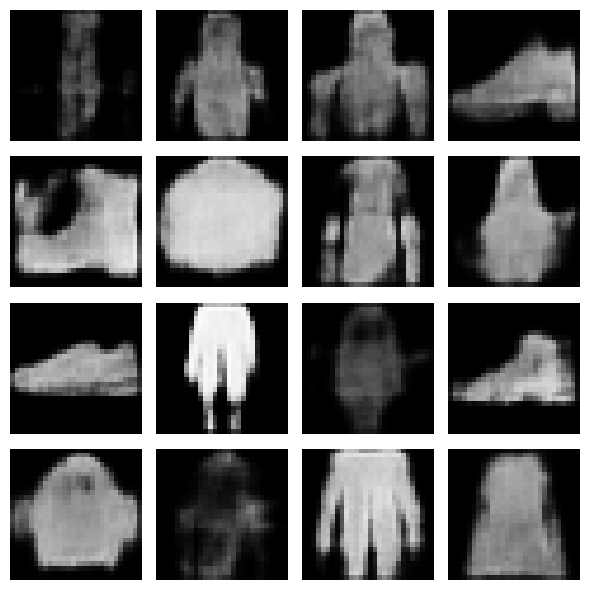

In [6]:
# 4x4 grid of generated samples
vae.eval()
with torch.no_grad():
    samples = vae.decode(torch.randn(16, LATENT_DIM, device=device)).cpu()

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, img in zip(axes.flat, samples):
    ax.imshow(img.squeeze(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.tight_layout()
plt.savefig("images/p1_vae_samples.png", dpi=150, bbox_inches="tight")
plt.show()

Per-dimension KL: [0.52 2.48 0.47 1.74 1.39 0.92 1.84 1.07 0.85 1.32 0.69 0.74 0.15 0.72
 0.67 1.73]
Exploring dimensions 1 (horizontal) and 6 (vertical)


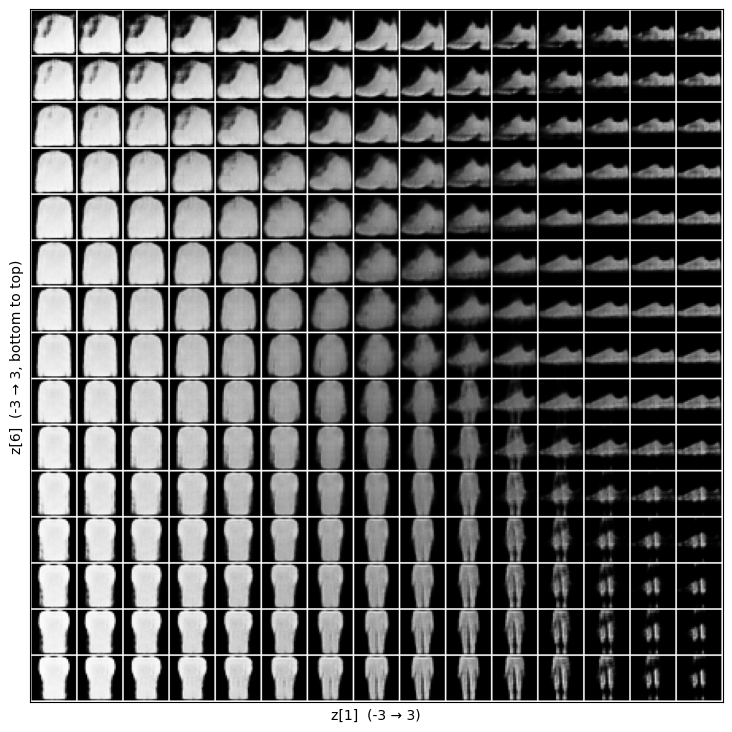

In [7]:
# Latent space exploration: vary two dimensions, fix the rest at 0.
# Pick the two dimensions the encoder actually uses most
with torch.no_grad():
    x_test, _ = next(iter(test_loader))
    mu, lv = vae.encode(x_test.to(device))
    kl_per_dim = (-0.5 * (1 + lv - mu.pow(2) - lv.exp())).mean(0)
d1, d2 = kl_per_dim.topk(2).indices.tolist()
print("Per-dimension KL:", np.round(kl_per_dim.cpu().numpy(), 2))
print(f"Exploring dimensions {d1} (horizontal) and {d2} (vertical)")

N = 15
vals = torch.linspace(-3, 3, N)
z = torch.zeros(N * N, LATENT_DIM)
for r in range(N):
    for c in range(N):
        z[r * N + c, d1] = vals[c]
        z[r * N + c, d2] = vals[N - 1 - r]
with torch.no_grad():
    grid_imgs = vae.decode(z.to(device)).cpu()

grid = make_grid(grid_imgs, nrow=N, padding=1, pad_value=1.0)
plt.figure(figsize=(9, 9))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
plt.xlabel(f"z[{d1}]  (-3 \u2192 3)"); plt.ylabel(f"z[{d2}]  (-3 \u2192 3, bottom to top)")
plt.xticks([]); plt.yticks([])
plt.savefig("images/p1_latent_grid.png", dpi=150, bbox_inches="tight")
plt.show()

Latent space interpretation:

What do the two dimensions seem to encode?

Answer: The vertical dimension appears to control the width and overall shape of the fashion items. At the bottom of the grid, the generated images look like narrow, tall items with a gap between them. Towards the top, the items become wider and more solid in shape, resembling tops or shirts.

The horizontal dimension seems to influence the brightness and possibly the type of item being generated. Moving from left to right, the images gradually become darker and less filled. On the right side, some generated images even resemble sneakers rather than clothing.

Written analysis:

How does your VAE compare to the MNIST VAE? Are the outputs sharper, blurrier, more or less recognisable? What properties of your dataset make it harder or easier to generate from?

Answer:

My FashionMNIST VAE produces outputs that are generally blurrier and less distinct than the outputs from the MNIST VAE. While the generated images are still somewhat recognisable, it can sometimes be difficult to identify the exact type of clothing because different items have similar shapes and features. For example, shirts and t-shirts can look very similar in the generated samples.

Compared to MNIST, FashionMNIST is a more challenging dataset for a VAE to generate images from. MNIST contains handwritten digits that are relatively simple. Each digit has a fairly distinct shape, which makes it easier for the model to learn patterns and generate recognisable outputs.

FashionMNIST contains more complex images of clothing, shoes and accessories. These items have larger solid shapes, different textures and more variations in their appearance. For example, two different types of tops may have very similar outlines, making it harder for the model to distinguish between them. Shoes and trousers may also have details that are difficult to reproduce accurately at a low image resolution.

Another reason the outputs appear blurry is that the VAE uses a reconstruction loss that encourages the model to reproduce the average appearance of similar images. This can result in smoother images where smaller details and sharp edges are lost.

Overall, the FashionMNIST VAE is able to learn the general shapes and characteristics of fashion items but generating clear and highly recognisable images is more difficult than generating handwritten digits with the MNIST VAE.

## Part 2 — GAN Stability Experiments
Same networks for all three versions; only the loss and learning rates change.

In [9]:
Z_DIM = 64

gan_transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
gan_data = datasets.FashionMNIST(root="./data", train=True, download=True, transform=gan_transform)
gan_loader = DataLoader(gan_data, batch_size=128, shuffle=True, drop_last=True)

class Generator(nn.Module):
    def __init__(self, z_dim=Z_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 512),   nn.LeakyReLU(0.2),
            nn.Linear(512, 784),   nn.Tanh(),
            nn.Unflatten(1, (1, 28, 28)),
        )
    def forward(self, z):
        return self.net(z)

class Critic(nn.Module):
    """Discriminator / critic. Outputs a raw score so it works for BCE-with-logits and for the Wasserstein loss"""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 256), nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
        )
    def forward(self, x):
        return self.net(x)

def gradient_penalty(D, real, fake):
    """WGAN-GP: penalise the critic's gradient norm on interpolated samples for deviating from 1."""
    b = real.size(0)
    eps = torch.rand(b, 1, 1, 1, device=device)
    inter = (eps * real + (1 - eps) * fake).requires_grad_(True)
    out = D(inter)
    grads = torch.autograd.grad(outputs=out, inputs=inter,
                                grad_outputs=torch.ones_like(out), create_graph=True)[0]
    grads = grads.view(b, -1)
    return ((grads.norm(2, dim=1) - 1) ** 2).mean()

def train_gan(kind, lr_g, lr_d, epochs=30, n_critic=5, lam=10.0, seed=0):
    """kind = 'bce' or 'wgan_gp'. Returns G and per-epoch loss histories."""
    torch.manual_seed(seed)
    G, D = Generator().to(device), Critic().to(device)
    betas = (0.5, 0.999) if kind == "bce" else (0.0, 0.9)
    opt_g = torch.optim.Adam(G.parameters(), lr=lr_g, betas=betas)
    opt_d = torch.optim.Adam(D.parameters(), lr=lr_d, betas=betas)
    bce = nn.BCEWithLogitsLoss()
    g_hist, d_hist = [], []
    for epoch in range(epochs):
        g_sum = d_sum = 0.0
        g_n = d_n = 0
        for i, (real, _) in enumerate(gan_loader):
            real = real.to(device)
            b = real.size(0)
            fake = G(torch.randn(b, Z_DIM, device=device))

            if kind == "bce":
                ones = torch.ones(b, 1, device=device)
                zeros = torch.zeros(b, 1, device=device)
                d_loss = bce(D(real), ones) + bce(D(fake.detach()), zeros)
                opt_d.zero_grad(); d_loss.backward(); opt_d.step()
                g_loss = bce(D(fake), ones)
                opt_g.zero_grad(); g_loss.backward(); opt_g.step()
                d_sum += d_loss.item(); d_n += 1
                g_sum += g_loss.item(); g_n += 1
            else:
                # Critic step (every batch)
                d_loss = D(fake.detach()).mean() - D(real).mean() + lam * gradient_penalty(D, real, fake.detach())
                opt_d.zero_grad(); d_loss.backward(); opt_d.step()
                d_sum += d_loss.item(); d_n += 1
                # Generator step (once every n_critic critic steps)
                if (i + 1) % n_critic == 0:
                    g_loss = -D(G(torch.randn(b, Z_DIM, device=device))).mean()
                    opt_g.zero_grad(); g_loss.backward(); opt_g.step()
                    g_sum += g_loss.item(); g_n += 1
        g_hist.append(g_sum / max(g_n, 1)); d_hist.append(d_sum / max(d_n, 1))
        print(f"Epoch {epoch + 1}/{epochs}  D loss: {d_hist[-1]:.3f}  G loss: {g_hist[-1]:.3f}")
    return G, g_hist, d_hist

def gan_samples(G, n):
    G.eval()
    with torch.no_grad():
        return ((G(torch.randn(n, Z_DIM, device=device)) + 1) / 2).clamp(0, 1).cpu()   # back to [0, 1]

def show_50(G, title, path):
    imgs = gan_samples(G, 50)
    fig, axes = plt.subplots(5, 10, figsize=(12, 6.5))
    for ax, img in zip(axes.flat, imgs):
        ax.imshow(img.squeeze(), cmap="gray", vmin=0, vmax=1); ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

def plot_losses(g_hist, d_hist, title, path):
    plt.figure(figsize=(6, 3.5))
    plt.plot(g_hist, label="G loss"); plt.plot(d_hist, label="D loss")
    plt.xlabel("epoch"); plt.title(title); plt.legend(); plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

Epoch 1/30  D loss: 0.692  G loss: 1.885
Epoch 2/30  D loss: 0.597  G loss: 2.876
Epoch 3/30  D loss: 0.806  G loss: 2.108
Epoch 4/30  D loss: 0.720  G loss: 2.322
Epoch 5/30  D loss: 0.760  G loss: 2.277
Epoch 6/30  D loss: 0.779  G loss: 2.088
Epoch 7/30  D loss: 0.833  G loss: 1.965
Epoch 8/30  D loss: 0.874  G loss: 1.927
Epoch 9/30  D loss: 0.911  G loss: 1.801
Epoch 10/30  D loss: 0.947  G loss: 1.704
Epoch 11/30  D loss: 0.959  G loss: 1.695
Epoch 12/30  D loss: 0.962  G loss: 1.633
Epoch 13/30  D loss: 0.996  G loss: 1.606
Epoch 14/30  D loss: 0.995  G loss: 1.557
Epoch 15/30  D loss: 1.009  G loss: 1.513
Epoch 16/30  D loss: 1.002  G loss: 1.521
Epoch 17/30  D loss: 1.007  G loss: 1.517
Epoch 18/30  D loss: 1.000  G loss: 1.497
Epoch 19/30  D loss: 1.008  G loss: 1.490
Epoch 20/30  D loss: 1.014  G loss: 1.484
Epoch 21/30  D loss: 1.016  G loss: 1.458
Epoch 22/30  D loss: 1.019  G loss: 1.453
Epoch 23/30  D loss: 1.025  G loss: 1.426
Epoch 24/30  D loss: 1.024  G loss: 1.442
E

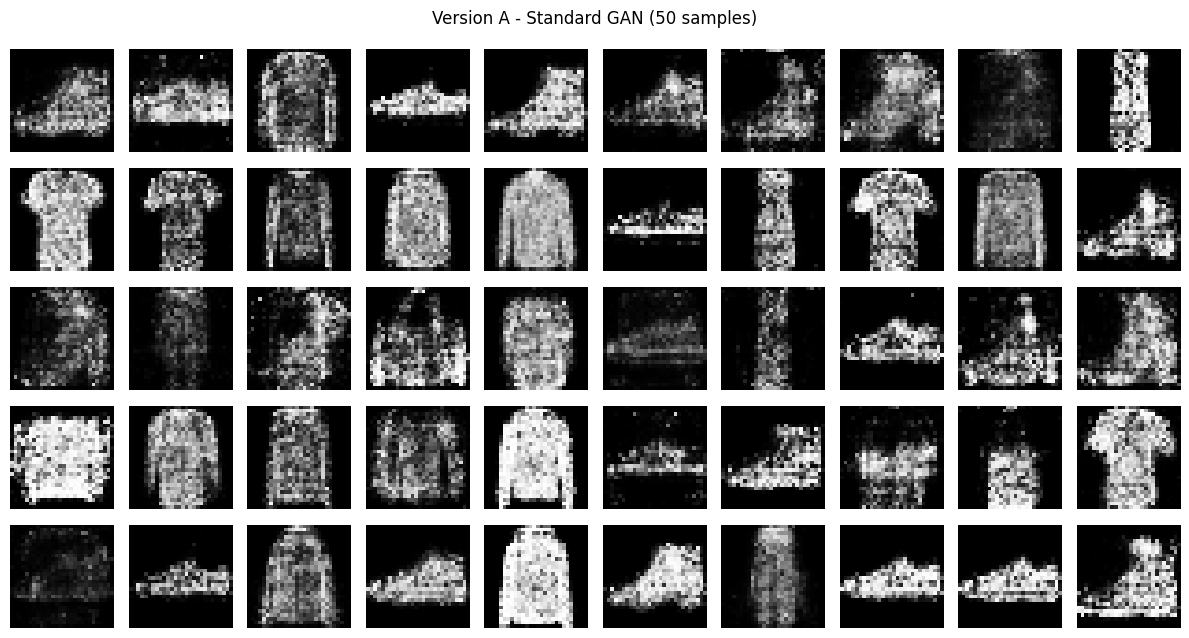

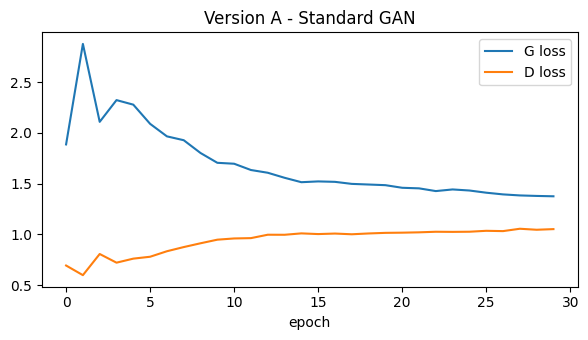

In [10]:
# Version A - Standard GAN: 30 epochs
G_A, gA, dA = train_gan("bce", lr_g=2e-4, lr_d=2e-4, epochs=30)
show_50(G_A, "Version A - Standard GAN (50 samples)", "images/p2_samples_A.png")
plot_losses(gA, dA, "Version A - Standard GAN", "images/p2_losses_A.png")

Epoch 1/30  D loss: 0.697  G loss: 1.919
Epoch 2/30  D loss: 0.695  G loss: 2.191
Epoch 3/30  D loss: 0.743  G loss: 2.085
Epoch 4/30  D loss: 0.779  G loss: 2.084
Epoch 5/30  D loss: 0.790  G loss: 2.099
Epoch 6/30  D loss: 0.797  G loss: 2.100
Epoch 7/30  D loss: 0.788  G loss: 2.115
Epoch 8/30  D loss: 0.786  G loss: 2.210
Epoch 9/30  D loss: 0.776  G loss: 2.222
Epoch 10/30  D loss: 0.776  G loss: 2.258
Epoch 11/30  D loss: 0.782  G loss: 2.228
Epoch 12/30  D loss: 0.789  G loss: 2.221
Epoch 13/30  D loss: 0.783  G loss: 2.246
Epoch 14/30  D loss: 0.807  G loss: 2.214
Epoch 15/30  D loss: 0.793  G loss: 2.245
Epoch 16/30  D loss: 0.792  G loss: 2.273
Epoch 17/30  D loss: 0.783  G loss: 2.297
Epoch 18/30  D loss: 0.782  G loss: 2.318
Epoch 19/30  D loss: 0.781  G loss: 2.345
Epoch 20/30  D loss: 0.772  G loss: 2.364
Epoch 21/30  D loss: 0.864  G loss: 2.229
Epoch 22/30  D loss: 0.768  G loss: 2.363
Epoch 23/30  D loss: 0.768  G loss: 2.370
Epoch 24/30  D loss: 0.769  G loss: 2.393
E

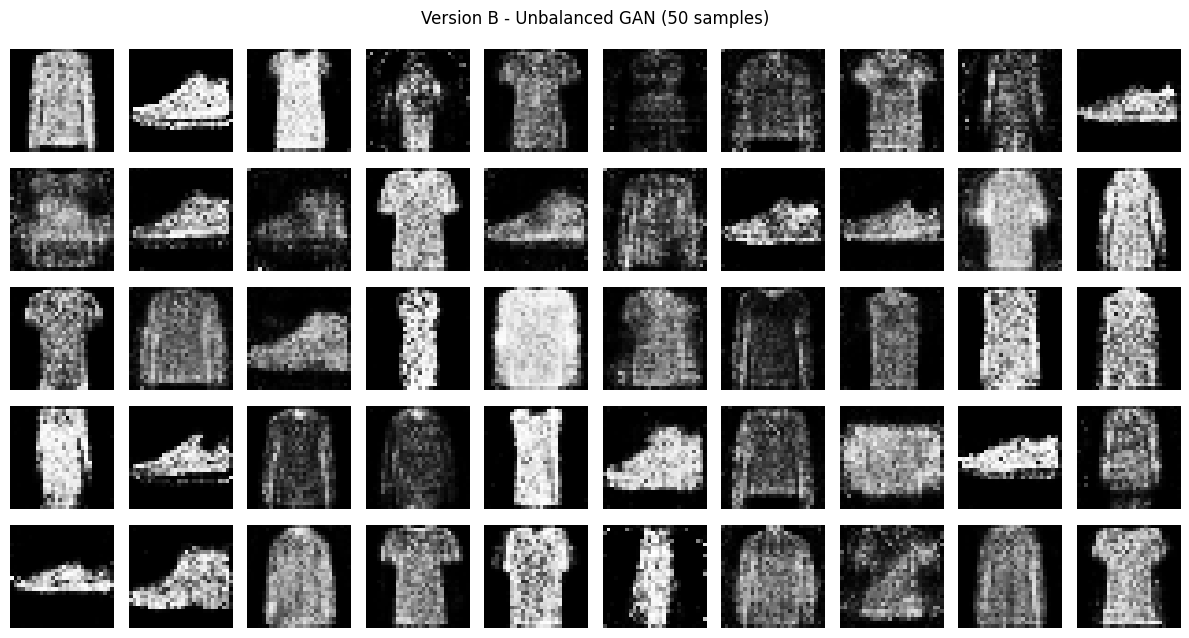

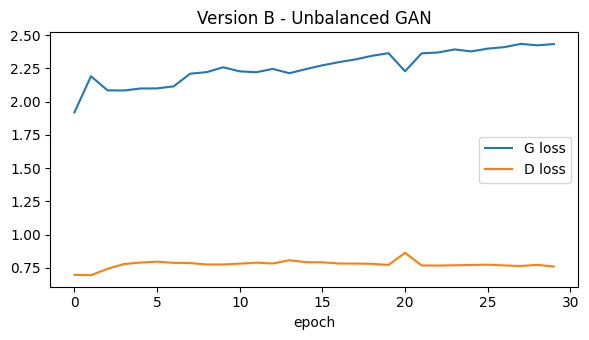

In [11]:
# Version B - Unbalanced GAN: 30 epochs
G_B, gB, dB = train_gan("bce", lr_g=2e-4, lr_d=2e-3, epochs=30)
show_50(G_B, "Version B - Unbalanced GAN (50 samples)", "images/p2_samples_B.png")
plot_losses(gB, dB, "Version B - Unbalanced GAN", "images/p2_losses_B.png")

Epoch 1/30  D loss: -9.928  G loss: -6.046
Epoch 2/30  D loss: -11.761  G loss: -3.447
Epoch 3/30  D loss: -8.720  G loss: -3.940
Epoch 4/30  D loss: -6.792  G loss: -2.846
Epoch 5/30  D loss: -5.734  G loss: -2.891
Epoch 6/30  D loss: -5.642  G loss: -1.234
Epoch 7/30  D loss: -5.513  G loss: 0.107
Epoch 8/30  D loss: -5.471  G loss: 1.083
Epoch 9/30  D loss: -5.462  G loss: 1.081
Epoch 10/30  D loss: -5.392  G loss: 0.634
Epoch 11/30  D loss: -5.347  G loss: 0.530
Epoch 12/30  D loss: -5.159  G loss: 0.197
Epoch 13/30  D loss: -4.960  G loss: -0.219
Epoch 14/30  D loss: -4.766  G loss: -0.324
Epoch 15/30  D loss: -4.556  G loss: -0.697
Epoch 16/30  D loss: -4.413  G loss: -1.087
Epoch 17/30  D loss: -4.239  G loss: -1.349
Epoch 18/30  D loss: -4.123  G loss: -1.290
Epoch 19/30  D loss: -4.020  G loss: -1.252
Epoch 20/30  D loss: -3.924  G loss: -0.998
Epoch 21/30  D loss: -3.844  G loss: -0.984
Epoch 22/30  D loss: -3.752  G loss: -0.960
Epoch 23/30  D loss: -3.657  G loss: -1.085
Ep

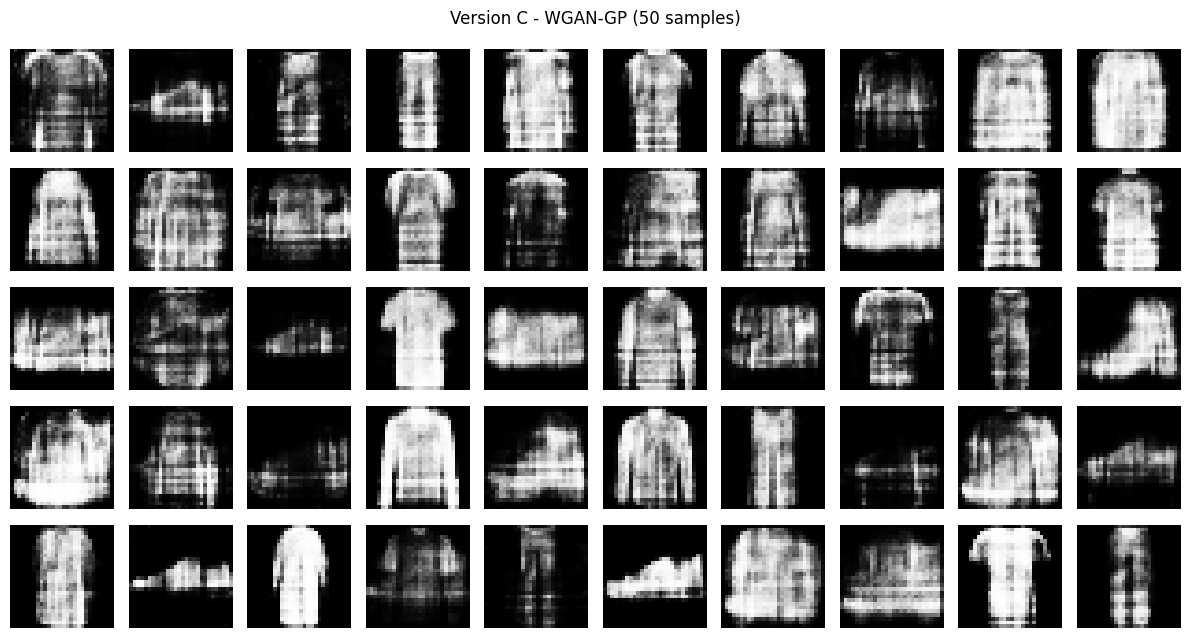

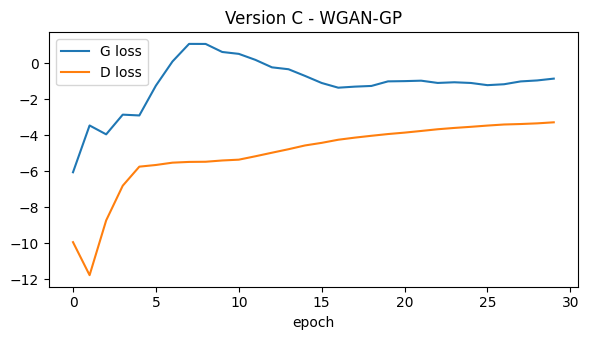

In [12]:
# Version C - Wasserstein loss + gradient penalty 30 epochs
G_C, gC, dC = train_gan("wgan_gp", lr_g=1e-4, lr_d=1e-4, epochs=30)
show_50(G_C, "Version C - WGAN-GP (50 samples)", "images/p2_samples_C.png")
plot_losses(gC, dC, "Version C - WGAN-GP", "images/p2_losses_C.png")

In [13]:
# FID: 500 generated images vs 500 real images for each version
def save_images(tensor, folder):
    os.makedirs(folder, exist_ok=True)
    for i, img in enumerate(tensor):
        save_image(img, f"{folder}/{i:04d}.png")

raw_train = datasets.FashionMNIST(root="./data", train=True, download=True, transform=to_tensor)
save_images(torch.stack([raw_train[i][0] for i in range(500)]), "fid/real")
save_images(gan_samples(G_A, 500), "fid/A")
save_images(gan_samples(G_B, 500), "fid/B")
save_images(gan_samples(G_C, 500), "fid/C")

def fid(path_a, path_b):
    out = subprocess.run(["python", "-m", "pytorch_fid", path_a, path_b, "--device", str(device)],
                         capture_output=True, text=True)
    m = re.search(r"FID:\s+([\d.]+)", out.stdout)
    if not m:
        print(out.stderr[-600:])
    return float(m.group(1)) if m else None

fid_scores = {v: fid("fid/real", f"fid/{v}") for v in ["A", "B", "C"]}
for v, s in fid_scores.items():
    print(f"Version {v}: FID = {s}")

Version A: FID = 174.91446541605328
Version B: FID = 158.14796435646423
Version C: FID = 158.81707030866568


Written conclusion

Does WGAN-GP actually fix mode collapse in your experiment? If not, what else could explain any remaining instability?

Answer:

WGAN-GP only partly fixed the problems in my experiment. Version B produced several item types but the images were noisy and speckled and sneakers and tops made up most of the samples. Version C samples were more varied and included trousers, boots and long sleeves but they were smeared and covered in stripes so they looked less recognisable than I expected. The remaining problems could be because the generator was updated only once per five critic steps so it had far fewer updates in 30 epochs. The small MLP networks, the learning rate and the noisy FID from only 500 images could also contribute.